# El EDA de mi proyecto

Es el mismo EDA que el del Titanic, con tus datos: las 9 preguntas, una detrás de otra. Al final se guardan los datos limpios en un CSV, que es el que lee la app.

Debajo de cada bloque hay una celda de texto para escribir lo que has visto y lo que has decidido, en una frase. Si no te acuerdas de cómo se hacía algo, mira titanic.ipynb, eda.ipynb o teoria_eda.ipynb.

## Mis datos

Haz doble clic aquí y escribe de dónde salen tus datos (con el enlace), qué es cada fila y qué pregunta quieres responder.

## 0. Comprobación

In [321]:
import pandas as pd
import matplotlib

print("Todo listo")

Todo listo


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [322]:
# 1.1 Cargo las ofertas de trabajo desde el CSV de la carpeta datos y enseño las 5 primeras filas
data_jobs = pd.read_csv("datos/data_jobs.csv")
data_jobs.head()


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


**1.2** ¿Cuántas filas y columnas tiene?

In [323]:
# 1.2 Tamaño de la tabla: (filas, columnas)
data_jobs.shape

(785741, 17)

**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [324]:
# 1.3 Tipo de cada columna y cuántos valores no vacíos tiene (si son menos que las filas, hay huecos)
data_jobs.info()

<class 'pandas.DataFrame'>
RangeIndex: 785741 entries, 0 to 785740
Data columns (total 17 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   job_title_short        785741 non-null  str    
 1   job_title              785740 non-null  str    
 2   job_location           784696 non-null  str    
 3   job_via                785733 non-null  str    
 4   job_schedule_type      773074 non-null  str    
 5   job_work_from_home     785741 non-null  bool   
 6   search_location        785741 non-null  str    
 7   job_posted_date        785741 non-null  str    
 8   job_no_degree_mention  785741 non-null  bool   
 9   job_health_insurance   785741 non-null  bool   
 10  job_country            785692 non-null  str    
 11  salary_rate            33067 non-null   str    
 12  salary_year_avg        22003 non-null   float64
 13  salary_hour_avg        10662 non-null   float64
 14  company_name           785723 non-null  str    

**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

In [325]:
# 1.4 Me quedo solo con las ofertas de España en una tabla nueva: ofertas
# .copy() hace una copia aparte para no tocar la tabla original (no lo hemos visto en clase)
ofertas = data_jobs[data_jobs["job_country"] == "Spain"].copy()
ofertas.shape

(25100, 17)

In [326]:
# 1.4 Me quedo con las 10 columnas que sirven para mis preguntas y para los filtros de la app
# Quito país y ubicación de búsqueda (siempre es España), los salarios (casi todos vacíos),
# el seguro médico (solo 3 ofertas lo mencionan) y job_type_skills (repite las habilidades)
ofertas = ofertas[["job_title_short", "job_title", "job_location", "job_work_from_home", "job_schedule_type", "job_skills", "company_name", "job_posted_date", "job_via", "job_no_degree_mention"]]
ofertas.shape

(25100, 10)

**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [327]:
# 1.5 Pongo los nombres de las columnas en español, cortos y sin tildes
ofertas.columns = ["puesto", "titulo", "ubicacion", "remoto", "jornada", "habilidades", "empresa", "fecha", "portal", "sin_titulo"]
ofertas.head()

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo
115,Data Scientist,Azure Big Data Engineer,"Madrid, Spain",False,Full-time,"['scala', 'azure']",FHIOS Smart Knowledge,2023-03-02 13:24:09,via BeBee,False
124,Data Scientist,DATA SCIENTIST,"Madrid, Spain",False,Full-time,"['sql', 'python', 'r', 'hadoop', 'spark', 'git...",Joboss,2023-05-03 13:46:14,via LinkedIn,False
226,Data Engineer,Data Engineer con Python,Spain,False,Full-time,['python'],Keyrus,2023-01-20 14:12:16,via LinkedIn,True
258,Data Engineer,Data Engineer,"Barcelona, Spain",False,Full-time,"['python', 'sql', 'postgresql', 'gcp', 'aws', ...",Michael Page,2023-02-26 13:10:34,via BeBee,True
264,Senior Data Engineer,Senior Engineer- MS,"Madrid, Spain",False,Full-time,['outlook'],NTT,2023-02-08 21:45:53,via BeBee,False


Lo que he visto y lo que he decidido:

- La tabla original tiene 785.741 ofertas de todo el mundo y 17 columnas. Me quedo con las de España: 25.100.
- La fecha y las habilidades vienen como texto, no como fecha ni como lista.
- Quito 7 columnas: el país y la ubicación de búsqueda (después del filtro siempre es España), los tres de salario (más del 99 % vacíos), el seguro médico (solo 3 ofertas lo mencionan) y job_type_skills (son las mismas habilidades que job_skills, agrupadas por tipo).
- Pongo los nombres de las columnas en español, cortos y sin tildes.
- El tipo de puesto no siempre coincide con el título de la oferta (por ejemplo, un "Data Scientist" cuyo título es "Azure Big Data Engineer").

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [328]:
# 2.1 Cuento cuántos huecos tiene cada columna
ofertas.isnull().sum()

puesto            0
titulo            0
ubicacion         0
remoto            0
jornada          99
habilidades    3083
empresa           0
fecha             0
portal            0
sin_titulo        0
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

In [329]:
# 2.2 Porcentaje de huecos de cada columna, redondeado a un decimal
(ofertas.isnull().mean()*100).round(1)

puesto          0.0
titulo          0.0
ubicacion       0.0
remoto          0.0
jornada         0.4
habilidades    12.3
empresa         0.0
fecha           0.0
portal          0.0
sin_titulo      0.0
dtype: float64

**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [330]:
# 2.3 Quito las filas sin jornada: son solo 99 ofertas (0,4 %), no cambian los resultados
ofertas = ofertas.dropna(subset=["jornada"])
ofertas.shape

(25001, 10)

**Los huecos de habilidades (12,3 %) los dejo a propósito: esas ofertas me siguen sirviendo para analizar el puesto, la ubicación, el remoto y la jornada. Cuando cuente las habilidades, solo usaré las ofertas que las tienen. Si las quitara perdería información, y si las rellenara me estaría inventando un dato.**

**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [331]:
# 2.4 Compruebo que ya no quedan huecos en jornada; los de habilidades los dejo a propósito
ofertas.isnull().sum()

puesto            0
titulo            0
ubicacion         0
remoto            0
jornada           0
habilidades    3063
empresa           0
fecha             0
portal            0
sin_titulo        0
dtype: int64

**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [332]:
# 2.5 Busco huecos disfrazados en las columnas de texto, empezando por el tipo de puesto
ofertas["puesto"].value_counts()

puesto
Data Engineer                6720
Data Scientist               5560
Data Analyst                 5152
Software Engineer            1574
Business Analyst             1500
Senior Data Engineer         1374
Senior Data Scientist        1344
Senior Data Analyst           615
Machine Learning Engineer     597
Cloud Engineer                565
Name: count, dtype: int64

In [333]:
# 2.5 Tipos de jornada: no hay huecos disfrazados, pero hay muchas combinaciones
ofertas["jornada"].value_counts()

jornada
Full-time                                24010
Contractor                                 284
Internship                                 272
Part-time                                  199
Full-time and Internship                    53
Full-time and Part-time                     50
Temp work                                   40
Full-time and Temp work                     30
Full-time and Contractor                    16
Part-time and Internship                    14
Contractor and Temp work                     9
Full-time, Part-time, and Internship         6
Full-time, Part-time, and Temp work          3
Part-time and Contractor                     3
Part-time and Temp work                      3
Full-time, Contractor, and Temp work         2
Temp work and Internship                     2
Full-time and Per diem                       2
Full-time, Temp work, and Internship         1
Contractor, Temp work, and Internship        1
Contractor and Full-time                     1
Name:

In [334]:
# 2.5 Ubicaciones: "Spain" (no dice la ciudad) y "Anywhere" (en cualquier sitio) no son ciudades
ofertas["ubicacion"].value_counts()

ubicacion
Madrid, Spain                 9762
Barcelona, Spain              4201
Spain                         2920
Anywhere                      2639
Valencia, Spain                783
                              ... 
San Fernando, Spain              1
La Puebla del Río, Spain         1
Sant Joan d'Alacant, Spain       1
Alburquerque, Spain              1
Santa Bàrbara, Spain             1
Name: count, Length: 380, dtype: int64

In [335]:
# 2.5 Cambio "Spain" por "Sin especificar" y "Anywhere" por "Remoto" para que se entiendan en la app
ofertas["ubicacion"] = ofertas["ubicacion"].replace({"Spain": "Sin especificar", "Anywhere": "Remoto"})

In [336]:
# 2.5 Compruebo el cambio: ya no aparecen "Spain" ni "Anywhere"
ofertas["ubicacion"].value_counts()

ubicacion
Madrid, Spain                 9762
Barcelona, Spain              4201
Sin especificar               2920
Remoto                        2639
Valencia, Spain                783
                              ... 
San Fernando, Spain              1
La Puebla del Río, Spain         1
Sant Joan d'Alacant, Spain       1
Alburquerque, Spain              1
Santa Bàrbara, Spain             1
Name: count, Length: 380, dtype: int64

In [337]:
# 2.5 Portales donde se publicó la oferta: no hay huecos, pero todos empiezan por "via "
ofertas["portal"].value_counts()

portal
via BeBee                                                11900
via LinkedIn                                              5893
via Trabajo.org                                           2559
via Indeed                                                 857
via Recruit.net                                            752
                                                         ...  
via Aicareers                                                1
via Jobs MAPFRE                                              1
via Best Suitable Jobs For Your Skills And Experience        1
via Jobs At Nestlé | Nestlé Global - Nestle                  1
via Www.finden.at                                            1
Name: count, Length: 303, dtype: int64

Lo que he visto y lo que he decidido:

- Solo hay huecos en dos columnas: jornada (99 ofertas, 0,4 %) y habilidades (3.083 ofertas, 12,3 %).
- Quito las 99 ofertas sin jornada, porque son muy pocas y no cambian los resultados. Quedan 25.001.
- Dejo a propósito los huecos de habilidades: esas ofertas me sirven para el resto del análisis y no quiero inventarme el dato.
- En ubicación hay un hueco disfrazado: "Spain" significa que la oferta no dice la ciudad. Lo cambio por "Sin especificar". "Anywhere" no es un hueco, significa que se puede trabajar desde cualquier sitio: lo cambio por "Remoto".
- La jornada tiene 21 combinaciones distintas, pero el 96 % son "Full-time".
- Todos los portales empiezan por "via " (pendiente de decidir si lo quito).

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [338]:
# 3.1 Cuento las filas repetidas exactas (iguales en las 10 columnas)
ofertas.duplicated().sum()

np.int64(1)

**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [339]:
# 3.2 Enseño la oferta repetida y su original para compararlas
# keep=False marca también la fila original, para ver las dos (no lo hemos visto en clase)
ofertas[ofertas.duplicated(keep=False)]

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo
469737,Data Analyst,Data Analyst,"Madrid, Spain",False,Full-time,NaN,Randstad,2023-06-01 14:46:27,via BeBee,True
484337,Data Analyst,Data Analyst,"Madrid, Spain",False,Full-time,NaN,Randstad,2023-06-01 14:46:27,via BeBee,True


**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

In [340]:
# 3.3 Quito la copia: es la misma oferta de Randstad publicada dos veces en el mismo segundo
ofertas = ofertas.drop_duplicates()
ofertas.shape

(25000, 10)

**3.4** *(Propuesta del profesor)* ¿Aparece la misma oferta (mismo título, empresa y ubicación) varias veces con distinta fecha? Si se repite, sus habilidades se contarían varias veces. Decide qué haces con esas ofertas, y hazlo.

In [341]:
# 3.4 Cuento las ofertas con el mismo título, empresa y ubicación aunque cambie la fecha
ofertas.duplicated(subset=["titulo", "empresa", "ubicacion"]).sum()

np.int64(5462)

In [342]:
# 3.4 Quito solo las que además tienen las mismas habilidades: son la misma oferta publicada varias veces.
# Si las habilidades cambian, son puestos distintos con el mismo título (por ejemplo, de agencias de selección)
ofertas = ofertas.drop_duplicates(subset=["titulo", "empresa", "ubicacion", "habilidades"])
ofertas.shape

(21192, 10)

Lo que he visto y lo que he decidido:

- Había 1 fila repetida exacta: la misma oferta de Data Analyst de Randstad en Madrid, publicada en BeBee el mismo día al mismo segundo. Es la misma oferta guardada dos veces, así que quito la copia. Quedan 25.000.
- A propuesta del profesor, busco también la misma oferta con distinta fecha (mismo título, empresa y ubicación): hay 5.462.
- No todas son la misma oferta: algunas agencias de selección (como Walters People) publican muchos "Data Engineer" en Madrid que piden habilidades distintas, así que son puestos diferentes.
- Quito solo las que además tienen las mismas habilidades (3.808), porque son la misma oferta publicada varias veces y sus habilidades se contarían de más. Quedan 21.192.

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

In [343]:
# Convierto las habilidades de texto a lista (código que me dio el profesor, no lo hemos visto en clase)
# Ejecutar una sola vez: si se repite, la columna se queda vacía
ofertas["habilidades"] = ofertas["habilidades"].str.strip("[]").str.replace("'", "").str.split(", ")
ofertas.head()

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo
115,Data Scientist,Azure Big Data Engineer,"Madrid, Spain",False,Full-time,"[scala, azure]",FHIOS Smart Knowledge,2023-03-02 13:24:09,via BeBee,False
124,Data Scientist,DATA SCIENTIST,"Madrid, Spain",False,Full-time,"[sql, python, r, hadoop, spark, git, jira]",Joboss,2023-05-03 13:46:14,via LinkedIn,False
226,Data Engineer,Data Engineer con Python,Sin especificar,False,Full-time,[python],Keyrus,2023-01-20 14:12:16,via LinkedIn,True
258,Data Engineer,Data Engineer,"Barcelona, Spain",False,Full-time,"[python, sql, postgresql, gcp, aws, linux]",Michael Page,2023-02-26 13:10:34,via BeBee,True
264,Senior Data Engineer,Senior Engineer- MS,"Madrid, Spain",False,Full-time,[outlook],NTT,2023-02-08 21:45:53,via BeBee,False


In [344]:
# Creo una columna de números: cuántas habilidades pide cada oferta
# .str.len() cuenta los elementos de cada lista (no lo hemos visto en clase)
ofertas["num_habilidades"] = ofertas["habilidades"].str.len()

In [345]:
# Compruebo que aparece la columna num_habilidades
ofertas.head()

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo,num_habilidades
115,Data Scientist,Azure Big Data Engineer,"Madrid, Spain",False,Full-time,"[scala, azure]",FHIOS Smart Knowledge,2023-03-02 13:24:09,via BeBee,False,2.0
124,Data Scientist,DATA SCIENTIST,"Madrid, Spain",False,Full-time,"[sql, python, r, hadoop, spark, git, jira]",Joboss,2023-05-03 13:46:14,via LinkedIn,False,7.0
226,Data Engineer,Data Engineer con Python,Sin especificar,False,Full-time,[python],Keyrus,2023-01-20 14:12:16,via LinkedIn,True,1.0
258,Data Engineer,Data Engineer,"Barcelona, Spain",False,Full-time,"[python, sql, postgresql, gcp, aws, linux]",Michael Page,2023-02-26 13:10:34,via BeBee,True,6.0
264,Senior Data Engineer,Senior Engineer- MS,"Madrid, Spain",False,Full-time,[outlook],NTT,2023-02-08 21:45:53,via BeBee,False,1.0


**4.1** Haz el describe. ¿Qué te llama la atención?

In [346]:
# 4.1 Resumen de cuántas habilidades piden las ofertas
ofertas["num_habilidades"].describe()

count    18497.000000
mean         5.372439
std          3.644176
min          1.000000
25%          3.000000
50%          5.000000
75%          7.000000
max         35.000000
Name: num_habilidades, dtype: float64

**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [347]:
# 4.2 Media y mediana del número de habilidades
print(ofertas["num_habilidades"].mean().round(2))
print(ofertas["num_habilidades"].median().round(2))

5.37
5.0


**4.3** Dibuja su histograma.

<Axes: >

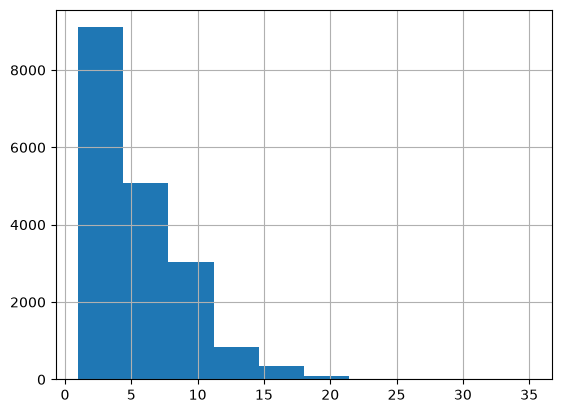

In [348]:
# 4.3 Histograma: cuántas ofertas piden cada número de habilidades
ofertas["num_habilidades"].hist()

**4.4** Haz lo mismo con otra columna de números.

In [349]:
# No tengo más columnas de números

Lo que he visto y lo que he decidido:

- Mi tabla no tenía columnas de números (remoto y sin_titulo son verdadero/falso, y quité los salarios), así que creo num_habilidades: cuántas habilidades pide cada oferta.
- 18.496 ofertas tienen habilidades. La media es 5,37 y la mediana 5: se parecen, así que no hay valores extremos que tiren mucho de la media.
- La mitad de las ofertas pide entre 3 y 7 habilidades. Casi 6 de cada 10 piden entre 1 y 5, y lo más habitual son 2, 3 o 4.
- El 4.4 me lo salto: no tengo otra columna de números. El salario solo lo traen 144 ofertas de España, así que no sirve para sacar conclusiones (lo he consultado con el profesor).

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

In [350]:
# 5.1 Las 5 ofertas que piden más habilidades
ofertas.sort_values("num_habilidades", ascending=False).head(5)

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo,num_habilidades
289532,Data Analyst,Data Analyst,"Madrid, Spain",False,Full-time,"[python, r, sql, html, css, javascript, sas, s...","Madrid, Spain",2023-07-31 18:07:29,via BeBee,False,35.0
150398,Machine Learning Engineer,Desarrollador/a de Machine Learning,"Palma, Spain",False,Contractor,"[python, java, c++, r, sas, sas, sql, html, cs...",beBee Professionals,2023-09-12 08:34:34,via BeBee,False,30.0
75216,Data Scientist,Expert AI & Data Science,"Valencian Community, Spain",False,Full-time,"[python, java, c++, php, sql, nosql, scala, ba...",NLP PEOPLE,2023-01-08 00:19:45,via Recruit.net,False,29.0
438449,Data Engineer,Data Engineer Chapter Lead,Remoto,True,Full-time,"[python, sql, nosql, mongodb, mongodb, scala, ...",Clevertask,2023-07-03 16:18:20,via Indeed,True,26.0
231912,Data Engineer,Data Engineer,"Madrid, Spain",False,Full-time,"[mongodb, mongodb, python, bash, scala, go, ru...",Toughbyte Ltd,2023-10-26 07:25:54,via BeBee,False,26.0


**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

In [351]:
# 5.2 Las 5 ofertas que piden menos habilidades
ofertas.sort_values("num_habilidades", ascending=True).head(5)

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo,num_habilidades
603431,Data Analyst,Junior Data Analyst,Sin especificar,False,Full-time,[excel],Mur&Partners,2023-09-01 09:39:16,via LinkedIn,False,1.0
319044,Data Analyst,Digital Analyst,Remoto,True,Full-time,[looker],The Cocktail,2023-11-15 17:26:45,via LinkedIn,False,1.0
521117,Data Engineer,Data Engineer SSIS,"Barcelona, Spain",False,Full-time,[ssis],Keyrus US,2023-08-17 11:25:35,via Keyrus US - Talentify,True,1.0
435518,Data Engineer,Data Engineer/ Programador Prácticas,"Mairena del Aljarafe, Spain",False,Internship,[power bi],Servinform,2023-11-20 16:24:58,via LinkedIn,False,1.0
570128,Data Engineer,Data Quality Engineer,"Valencia, Spain",False,Full-time,[sql],Romeu,2023-12-28 09:34:32,via LinkedIn,True,1.0


**5.3** Haz el diagrama de caja de esa columna.

<Axes: >

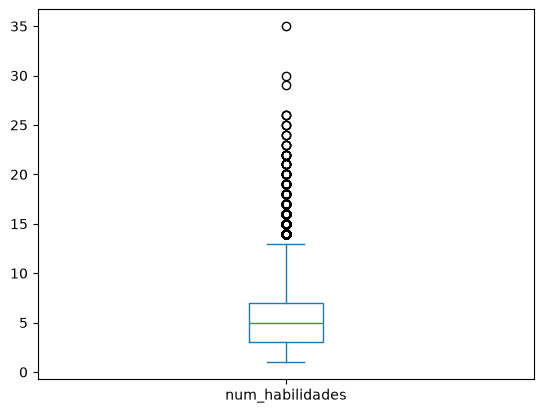

In [352]:
# 5.3 Diagrama de caja del número de habilidades
ofertas["num_habilidades"].plot.box()

In [353]:
# 5.3 Cuento los valores extremos: las ofertas que piden más de 13 habilidades
(ofertas["num_habilidades"] > 13).sum()

np.int64(654)

**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

In [354]:
# 5.4 Quito la oferta de 35 habilidades: está mal recogida (la empresa es una ciudad y tiene habilidades repetidas)
# Las 654 con más de 13 se quedan: son puestos exigentes reales
ofertas = ofertas[ofertas["num_habilidades"] != 35]
ofertas.shape

(21191, 11)

In [355]:
# 5.4 Busco ofertas donde la empresa se llama igual que la ubicación (una ciudad en lugar de una empresa)
ofertas[ofertas["empresa"] == ofertas["ubicacion"]]

,puesto,titulo,ubicacion,remoto,jornada,habilidades,empresa,fecha,portal,sin_titulo,num_habilidades
343381,Software Engineer,Lead Engineer 1,"Barcelona, Spain",False,Full-time,[assembly],"Barcelona, Spain",2023-10-18 23:27:33,via BeBee,False,1.0
436659,Data Scientist,"Staff (Lead) Data Scientist (Remote, Canada)","Madrid, Spain",False,Full-time,"[python, matplotlib, tableau]","Madrid, Spain",2023-11-15 16:26:50,via BeBee,False,3.0
737489,Business Analyst,Inside Sales with English and Finnish,"Madrid, Spain",False,Full-time,NaN,"Madrid, Spain",2023-07-28 21:21:33,via BeBee,False,NaN
760552,Data Analyst,"Clinical Trial Data Analyst, Madrid","Madrid, Spain",False,Full-time,[excel],"Madrid, Spain",2023-11-14 20:46:17,via BeBee,False,1.0


In [356]:
# 5.4 Cambio las empresas que son ciudades por "Sin especificar"
ofertas["empresa"] = ofertas["empresa"].replace({"Madrid, Spain": "Sin especificar", "Barcelona, Spain": "Sin especificar", "Madrid": "Sin especificar", "Marbella": "Sin especificar", "Spain": "Sin especificar", "Remote": "Sin especificar"})
(ofertas["empresa"] == "Sin especificar").sum()

np.int64(11)

Lo que he visto y lo que he decidido:

- En el diagrama de caja, los valores extremos empiezan en 14 habilidades: unas 650 ofertas.
- Se quedan: son puestos senior o muy técnicos (como "Expert AI & Data Science"), que piden muchas herramientas de verdad. No distorsionan los resultados.
- Quito la oferta de 35 habilidades: está mal recogida, porque la empresa es "Madrid, Spain" y tiene habilidades repetidas.
- Las ofertas con 1 sola habilidad son normales (por ejemplo, un Junior Data Analyst que solo pide Excel).
- En empresa hay lugares en lugar de nombres (Madrid, Marbella, Spain, Remote...). Los cambio por "Sin especificar": son 11 en total, contando 1 que ya venía así.
- Las empresas ocultas como "Confidencial" (unas 116, escritas de varias formas) las dejo como están: la empresa existe pero no quiere decir su nombre.
- El 8,9 % de las ofertas tiene alguna habilidad repetida en su lista (como "sas, sas"), así que en esas num_habilidades puede salir una de más.

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

In [357]:
# 6.1 Separo cada lista de habilidades en filas (una por habilidad) en una tabla aparte,
# para no perder la tabla de ofertas (explode me lo recomendó el profesor)
ofertas_por_habilidad = ofertas.explode("habilidades")
ofertas_por_habilidad.shape

(102034, 11)

In [358]:
# 6.1 Quito las habilidades repetidas dentro de una misma oferta (como "sas, sas") para no contarlas dos veces
ofertas_por_habilidad = ofertas_por_habilidad.drop_duplicates()
ofertas_por_habilidad.shape

(100339, 11)

In [359]:
# 6.1 Las 15 habilidades más pedidas, en número de ofertas
ofertas_por_habilidad["habilidades"].value_counts().head(15)

habilidades
python        10718
sql            9658
aws            4786
azure          4269
spark          3784
r              2921
power bi       2646
tableau        2544
excel          2422
scala          2067
git            2049
databricks     1769
java           1602
pyspark        1517
docker         1512
Name: count, dtype: int64

In [360]:
# 6.1 Las mismas 15 habilidades en porcentaje sobre el total de habilidades mencionadas
(ofertas_por_habilidad["habilidades"].value_counts(normalize=True).head(15)*100).round(2)

habilidades
python        10.98
sql            9.89
aws            4.90
azure          4.37
spark          3.88
r              2.99
power bi       2.71
tableau        2.61
excel          2.48
scala          2.12
git            2.10
databricks     1.81
java           1.64
pyspark        1.55
docker         1.55
Name: proportion, dtype: float64

**6.2** Dibújalo en barras.

<Axes: title={'center': '15 habilidades más pedidas en las ofertas de datos en España'}, xlabel='habilidades'>

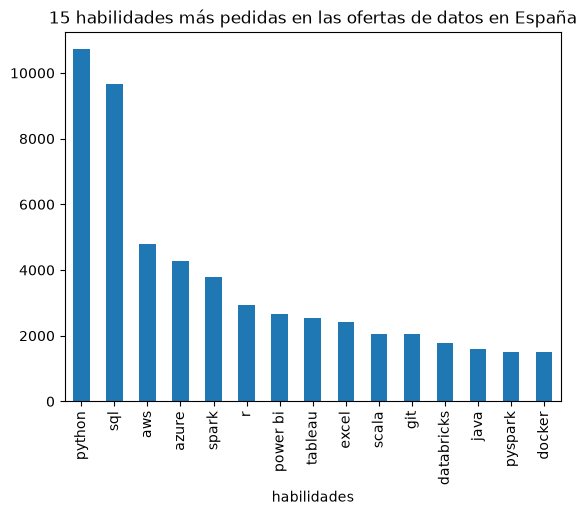

In [361]:
# 6.2 Gráfico de barras de las 15 habilidades más pedidas
ofertas_por_habilidad["habilidades"].value_counts().head(15).plot(kind="bar", title="15 habilidades más pedidas en las ofertas de datos en España")

Lo que he visto y lo que he decidido:

- Para contar habilidades separo cada lista en filas (una por habilidad) en una tabla aparte, ofertas_por_habilidad, para no perder la tabla de ofertas.
- Quito las habilidades repetidas dentro de una misma oferta (1.695), para no contarlas dos veces.
- Hay 227 habilidades distintas. Las más pedidas son Python (10.718 ofertas), SQL (9.658) y AWS (4.786).
- Python es el 11 % de todas las habilidades mencionadas y SQL casi el 10 %.

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

In [362]:
# 7.1 Media y mediana de habilidades que pide cada tipo de puesto, de más a menos
print((ofertas.groupby("puesto")["num_habilidades"].mean().round(2)).sort_values(ascending=False))

print((ofertas.groupby("puesto")["num_habilidades"].median()).sort_values(ascending=False))

puesto
Senior Data Engineer         7.28
Machine Learning Engineer    6.33
Data Engineer                6.29
Software Engineer            5.65
Cloud Engineer               5.39
Senior Data Scientist        5.33
Data Scientist               5.17
Senior Data Analyst          4.70
Data Analyst                 4.06
Business Analyst             3.48
Name: num_habilidades, dtype: float64
puesto
Senior Data Engineer         7.0
Data Engineer                6.0
Machine Learning Engineer    6.0
Cloud Engineer               5.0
Senior Data Scientist        5.0
Software Engineer            5.0
Data Analyst                 4.0
Data Scientist               4.0
Senior Data Analyst          4.0
Business Analyst             3.0
Name: num_habilidades, dtype: float64


**7.2** Haz otra comparación con otra columna de grupos.

In [363]:
# 7.2 Comparo las ofertas que no mencionan título universitario (True) con las que sí (False)
print(ofertas.groupby("sin_titulo")["num_habilidades"].mean().round(2).sort_values(ascending=False))

print(ofertas.groupby("sin_titulo")["num_habilidades"].median().sort_values(ascending=False))

sin_titulo
False    5.39
True     5.35
Name: num_habilidades, dtype: float64
sin_titulo
False    5.0
True     5.0
Name: num_habilidades, dtype: float64


**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

In [364]:
# 7.3 Cuántas ofertas hay en cada grupo, para comprobar que ninguno tiene muy pocas
print(ofertas["puesto"].value_counts())

print(ofertas.groupby("sin_titulo").size())

puesto
Data Engineer                5724
Data Scientist               4528
Data Analyst                 4320
Software Engineer            1466
Business Analyst             1375
Senior Data Engineer         1138
Senior Data Scientist        1057
Machine Learning Engineer     541
Cloud Engineer                533
Senior Data Analyst           509
Name: count, dtype: int64
sin_titulo
False    12430
True      8761
dtype: int64


Lo que he visto y lo que he decidido:

- Los puestos de analista son los que menos habilidades piden: Business Analyst 3,5 y Data Analyst 4,1 de media. Los de ingeniería piden más: Data Engineer 6,3 y Senior Data Engineer 7,3, casi el doble que un Data Analyst.
- Las ofertas que no mencionan título universitario piden las mismas habilidades que las que sí lo piden (5,35 frente a 5,39 de media): no son más fáciles.
- Ningún grupo tiene pocas ofertas: el más pequeño, Senior Data Analyst, tiene 509, así que las medias son fiables.
- El 41 % de las ofertas (8.761 de 21.191) no menciona que haga falta título universitario.

## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

In [365]:
#No tengo dos columnas con números

**8.2** Haz el gráfico de puntos de esas dos columnas.

In [366]:
#No tengo dos columnas con números

Lo que he visto y lo que he decidido:

- Me salto el paso 8, de acuerdo con el profesor: para una correlación hacen falta dos columnas de números y solo tengo una, num_habilidades.
- La otra opción era el salario, pero solo lo traen 144 de las ofertas de España, demasiado pocas para sacar una conclusión fiable.

## 9. ¿Qué he aprendido?

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos, cada uno en una frase con un número. Añade otra con lo que has quitado o cambiado en los datos. Esto es lo que irá en el README y en la presentación.

**Mis tres hallazgos:**

1. **Python y SQL son la base:** de las 18.496 ofertas que dicen qué habilidades piden, 10.718 piden Python y 9.658 piden SQL. Ninguna otra habilidad llega ni a la mitad que ellas.
2. **Los puestos de analista son la puerta de entrada más accesible:** un Data Analyst pide de media 4,1 habilidades y un Business Analyst 3,5, frente a las 6,3 de un Data Engineer y las 7,3 de un Senior Data Engineer.
3. **El título no es imprescindible, las habilidades sí:** el 41 % de las ofertas (8.761 de 21.191) no menciona que haga falta título universitario, pero piden las mismas habilidades que el resto (5,4 de media).

**Lo que he quitado o cambiado en los datos:** de 785.741 ofertas de todo el mundo me quedo con las 25.100 de España y con 10 de las 17 columnas. Quito 99 ofertas sin jornada, 1 repetida exacta, 3.808 publicadas varias veces y 1 mal recogida: quedan 21.191. Cambio "Spain" por "Sin especificar" y "Anywhere" por "Remoto" en la ubicación, y las empresas que eran lugares por "Sin especificar". Dejo a propósito los huecos de habilidades, y creo la columna num_habilidades para tener un número que analizar. Son datos de 2023, pueden no reflejar del todo el mercado actual y la realidad que nos tocará vivir cuando acabemos el Bootcamp, pero puede servirnos como referencia para salir al mercado laboral en busca de oportunidades.

## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

Resultado esperado: un archivo nuevo, datos_limpios.csv, en la carpeta datos.

In [367]:
# 10.1 Vuelvo a convertir las habilidades de lista a texto ("sql, python") para guardarlas en el CSV
# .str.join me lo dio el profesor (no lo hemos visto en clase). Ejecutar una sola vez
# Guardo la tabla limpia en datos/datos_limpios.csv, que es el archivo que lee la app
ofertas["habilidades"] = ofertas["habilidades"].str.join(", ")
ofertas.to_csv("datos/datos_limpios.csv", index=False)